In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

pd.set_option('display.max_columns', None)

In [9]:
df = pd.read_csv('../data/fraud_oracle.csv')
print('Rows and columns:', df.shape)
display(df.head())
display(pd.DataFrame({'Data type': df.dtypes.astype(str),
                      'Missing values': df.isna().sum(),
                      'Unique values': df.nunique()}))
print('Duplicate rows:', df.duplicated().sum())
print('Rows with Age = 0:', (df['Age'] == 0).sum())

Rows and columns: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


,Data type,Missing values,Unique values
Month,str,0,12
WeekOfMonth,int64,0,5
DayOfWeek,str,0,7
Make,str,0,19
AccidentArea,str,0,2
DayOfWeekClaimed,str,0,8
MonthClaimed,str,0,13
WeekOfMonthClaimed,int64,0,5
Sex,str,0,2
MaritalStatus,str,0,4


Duplicate rows: 0
Rows with Age = 0: 320


### I am keeping the remaining columns because we assume they are available when a claim is filed. We still need to confirm this with the data dictionary, especially for DriverRating, VehiclePrice, and PastNumberOfClaims. The columns below are excluded from this baseline as they are not all confirmed cases of leakage.

# Feature audit and final working decisions

In [10]:
# These columns should be out of the baseline for now.
# Some may contain information we would not know when a claim is first filed.
drop_reasons = {
    'Fault': 'Fault might be decided after an investigation.',
    'PolicyNumber': 'An ID number that also closely follows the year.',
    'RepNumber': 'An employee ID; we do not know when they were assigned.',
    'AgeOfPolicyHolder': 'The youngest age group appears only when Age is 0.',
    'PoliceReportFiled': 'The police report might be filed later.',
    'WitnessPresent': 'Witnesses might be found during the investigation.',
    'NumberOfSuppliments': 'More supplements could be added after filing.',
    'AddressChange_Claim': 'We need to confirm what this column means.',
    'Year': 'Used for the train/test split, not as a model input.'
}

# Showing what columns that are being dropped and the reasons for dropping them. 
drop_summary = pd.DataFrame(
    drop_reasons.items(),
    columns=['Column to drop', 'Reason']
)

display(drop_summary)

# Keep the remaining columns, excluding the label as well 
kept_columns = [
    column for column in df.columns
    if column not in drop_reasons and column != 'FraudFound_P'
]

print('Columns we are keeping:')
for column in kept_columns:
    print('-', column)

print('\nNumber of columns kept:', len(kept_columns))

,Column to drop,Reason
0,Fault,Fault might be decided after an investigation.
1,PolicyNumber,An ID number that also closely follows the year.
2,RepNumber,An employee ID; we do not know when they were ...
3,AgeOfPolicyHolder,The youngest age group appears only when Age i...
4,PoliceReportFiled,The police report might be filed later.
5,WitnessPresent,Witnesses might be found during the investigat...
6,NumberOfSuppliments,More supplements could be added after filing.
7,AddressChange_Claim,We need to confirm what this column means.
8,Year,"Used for the train/test split, not as a model ..."


Columns we are keeping:
- Month
- WeekOfMonth
- DayOfWeek
- Make
- AccidentArea
- DayOfWeekClaimed
- MonthClaimed
- WeekOfMonthClaimed
- Sex
- MaritalStatus
- Age
- PolicyType
- VehicleCategory
- VehiclePrice
- Deductible
- DriverRating
- Days_Policy_Accident
- Days_Policy_Claim
- PastNumberOfClaims
- AgeOfVehicle
- AgentType
- NumberOfCars
- BasePolicy

Number of columns kept: 23


# Create one training/hold-out split

In [11]:
train_df = df[df['Year'].isin([1994, 1995])].copy()
test_df = df[df['Year'] == 1996].copy()

assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(test_df.index)

split_summary = pd.DataFrame({
    'Split': ['Training: 1994–1995', 'Hold-out: 1996'],
    'Claims': [len(train_df), len(test_df)],
    'Fraud cases': [train_df['FraudFound_P'].sum(), test_df['FraudFound_P'].sum()],
    'Fraud rate': [train_df['FraudFound_P'].mean(), test_df['FraudFound_P'].mean()]
})
display(split_summary)

,Split,Claims,Fraud cases,Fraud rate
0,Training: 1994–1995,11337,710,0.062627
1,Hold-out: 1996,4083,213,0.052168


# Clean missing ages using the training median

In [12]:
for data in [train_df, test_df]:
    data['AgeMissing'] = ((data['Age'] == 0) | data['Age'].isna()).astype(int)
    data['Age'] = data['Age'].replace(0, np.nan)
    for column in ['MonthClaimed', 'DayOfWeekClaimed']:
        data[column] = data[column].replace('0', 'Unknown').fillna('Unknown')

training_median = train_df['Age'].median()
train_df['Age'] = train_df['Age'].fillna(training_median)
test_df['Age'] = test_df['Age'].fillna(training_median)
print('Training age median:', training_median)

input_columns = kept_columns + ['AgeMissing']
X_train = train_df[input_columns].copy()
y_train = train_df['FraudFound_P'].copy()
X_test = test_df[input_columns].copy()
y_test = test_df['FraudFound_P'].copy()
print('Input columns including AgeMissing:', len(input_columns))


Training age median: 38.0
Input columns including AgeMissing: 24


# One-hot encode categories 

In [13]:
category_columns = X_train.select_dtypes(include='object').columns.tolist()
category_columns += ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating']

X_train_encoded = pd.get_dummies(X_train, columns=category_columns, dtype=int)
X_test_encoded = pd.get_dummies(X_test, columns=category_columns, dtype=int)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
print('Training input shape:', X_train_encoded.shape)
print('Hold-out input shape:', X_test_encoded.shape)
assert not X_train_encoded.isna().any().any()
assert not X_test_encoded.isna().any().any()


Training input shape: (11337, 133)
Hold-out input shape: (4083, 133)


/var/folders/c_/qw90rlfj059_sqn8mghq5zs00000gn/T/ipykernel_38331/820445371.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_columns = X_train.select_dtypes(include='object').columns.tolist()


# Scale age and deductible. Fit the scaler on training only. Leave 0/1 columns unchanged

In [14]:
numeric_columns = ['Age', 'Deductible']
scaler = StandardScaler()
X_train_ready = X_train_encoded.copy()
X_test_ready = X_test_encoded.copy()
X_train_ready[numeric_columns] = scaler.fit_transform(X_train_encoded[numeric_columns])
X_test_ready[numeric_columns] = scaler.transform(X_test_encoded[numeric_columns])


# Train Logistic Regression Baseline

In [15]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_ready, y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

# Evaluate once on the hold-out
- Accuracy: fraction of all predictions that are correct.
- Precision: fraction of predicted fraud cases that actually are fraud.
- Recall: fraction of actual fraud cases caught.
- F1: combines precision and recall.
- Average precision (AP): a precision recall summary, labeled PR-AUC/AP. 

In [16]:
test_probabilities = model.predict_proba(X_test_ready)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(int)

never_fraud = np.zeros(len(y_test), dtype=int)
results = pd.DataFrame({
    'Approach': ['Always non-fraud reference', 'Logistic regression'],
    'Accuracy': [accuracy_score(y_test, never_fraud), accuracy_score(y_test, test_predictions)],
    'Precision': [0.0, precision_score(y_test, test_predictions, zero_division=0)],
    'Recall': [0.0, recall_score(y_test, test_predictions, zero_division=0)],
    'F1': [0.0, f1_score(y_test, test_predictions, zero_division=0)],
    'PR-AUC / AP': [average_precision_score(y_test, never_fraud),
                    average_precision_score(y_test, test_probabilities)]
})
display(results.round(4))
print('Percentage of claims flagged:', round(test_predictions.mean() * 100, 2))


,Approach,Accuracy,Precision,Recall,F1,PR-AUC / AP
0,Always non-fraud reference,0.9478,0.0000,0.000,0.0000,0.0522
1,Logistic regression,0.6111,0.0662,0.493,0.1168,0.0653


Percentage of claims flagged: 38.82


# Confusion Matrix

,Predicted non-fraud,Predicted fraud
Actual non fraud,2390,1480
Actual fraud,108,105


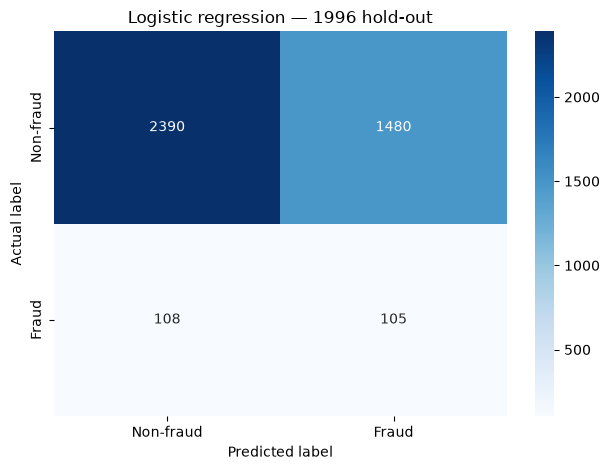

Correctly identified non-fraud: 2390
False alarms: 1480
Missed fraud: 108
Fraud cases caught: 105


In [18]:
matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])
display(pd.DataFrame(matrix, index=['Actual non fraud', 'Actual fraud'],
                     columns=['Predicted non-fraud', 'Predicted fraud']))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)
